# nmr.assignment

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.assignment')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "nmr.assignment",
  "status": "recorded_results",
  "source_sha256": {
    "assignment_carbon32_20261116.json": "c3d25150e5811b8987060e147f43d9add4f729e340da420b94425766e1e76540"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
    "nucleus": "13C",
    "peaks_ppm": {
      "length": 16,
      "first_values": [
        150.22,
        148.03,
        142.68,
        138.28,
        128.36,
        128.22,
        125.68,
        125.58
      ]
    },
    "note": "Assigned observed peaks; unmatched indices retained in output"
  },
  "output": {
    "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
    "symbol": "C",
    "mapped_smiles": "[C:1](=[C:2]([C:3]([C:4]([C:5]([C:6]([c:7]1[c:8]([H:33])[c:9]([H:34])[c:10]([H:35])[c:11]([H:36])[c:12]1[H:37])([H:31])[H:32])([H:29])[H:30])([H:27])[H:28])([H:25])[H:26])[c:13]1[c:14]([H:38])[c:15]([H:39])[c:16]([C:17]([C:18]([H:40])([H:41])[H:42])([C:19]([H:43])([H:44])[H:45])[C:20]([H:46])([H:47])[H:48])[c:21]([H:49])[c:22]1[H:50])([H:23])[H:24]",
    "atom_index_basis": "zero-based RDKit AddHs(input_smiles); atom-map numbers = index + 1",
    "equivalence": "topological symmetry including chirality; not pro

## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | molecules | 32 |
| recorded evaluation | recorded model | matched_peak_fraction_macro | 0.939238 |
| recorded evaluation | recorded model | matched_residual_mae_ppm | 0.899131 |
| recorded evaluation | recorded model | assignment_accuracy | not measured |


{
  "matched_peaks_this_example": 16,
  "residual_mae_ppm_this_example": 0.4150966421763089,
  "assignment_accuracy": null
}


## 预测／参考对照图

作为已知结构的候选指认流程合理，但尚无实验指认准确率。先验证原子标签和对称性，再决定微调。

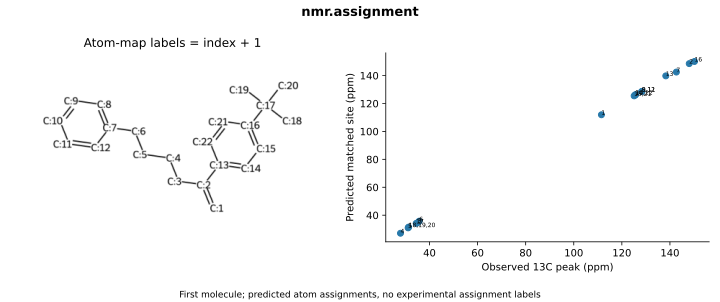

In [4]:
figure = render('nmr.assignment', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/nmr-assignment.md) · [Quick Start](../quickstart.md)
